# RQ3 -- Generation Quality: End-to-End Compliance Assessment Evaluation

**Research Question:** How accurately does the best-performing pipeline evaluate
ESRS compliance, and where does the system fail?

**Experimental design:** Single-condition characterisation study. The best-performing RQ1 pipeline — configured based on RQ2's findings (i.e., ESRS context is included only if it proved beneficial) — is evaluated against the full Golden Standard (12 questions × 17 companies = 204 samples). There is no paired comparison or ablation; the sole aim is to assess how well the system performs overall and to identify where it falls short.

**Two evaluation layers:**

| Layer | What it measures | Primary metric |
|---|---|---|
| A. Citation page overlap | Whether the system cites the correct evidence pages | Set-overlap Precision / Recall / F1 |
| B. LLM-judge rubric (5 dimensions, 1--5 each) | Factual correctness, completeness, grounding, citation usefulness, compliance quality | Mean dimension scores |

**Key methodological decisions:**
- Generated answers are **reused** from RQ2's `with_esrs_context` / `no_esrs_context`
  condition -- no new OpenAI generation calls.
- The LLM judge (Claude Sonnet 4.5) is used for evaluation.
- The generated compliance level is **withheld** from the judge to prevent
  anchoring bias (Zheng et al., 2024).
- All metrics are reported with **95% bootstrap confidence intervals**
  (10,000 resamples).
- A **stratified 20-sample manual audit subset** is exported as a CSV template
  for human calibration (same one like for RQ2).
- **Error analysis** breaks down performance by ESRS standard, identifies
  retrieval-generation gaps, and surfaces the lowest-scoring samples for
  qualitative inspection.

## 1. Setup and Imports

Load standard libraries, set up project paths, parse the `.env` file for API keys,
and configure the RQ2-to-RQ3 condition mapping. The `ESRS_CONTEXT_HELPS` boolean
selects which RQ2 condition is forwarded to RQ3: if RQ2 showed ESRS context helps,
we use `full_system`; otherwise `no_esrs_context`.

In [1]:
import sys
import os
import json
import hashlib
import warnings
import logging
from pathlib import Path
from collections import Counter, defaultdict
from statistics import mean
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=UserWarning)
logging.basicConfig(level=logging.WARNING)

# --- Project root and path setup ---
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

# --- Parse .env (comment-tolerant, no python-dotenv dependency) ---
_env_path = PROJECT_ROOT / ".env"
if _env_path.exists():
    for _line in _env_path.read_text().splitlines():
        _line = _line.strip()
        if _line and not _line.startswith("#") and "=" in _line:
            _k, _, _v = _line.partition("=")
            _k = _k.strip()
            if _k:
                os.environ.setdefault(_k, _v.strip().strip('"').strip("'"))

from rag.config.settings import (
    GOLDEN_STANDARD_PATH, RQ2_RESULTS_DIR, RQ3_RESULTS_DIR,
    ensure_dirs,
)

ensure_dirs()

# ---------------------------------------------------------------------------
# RQ2 -> RQ3 Configuration
# ---------------------------------------------------------------------------
# Read the RQ2 finding dynamically from the RQ2 aggregate results.
# This boolean controls which RQ2 condition RQ3 evaluates:
#   False -> no_esrs_context  (ESRS context had no significant effect)
#   True  -> full_system      (ESRS context significantly helped)
from rag.config.settings import load_esrs_context_decision
ESRS_CONTEXT_HELPS = load_esrs_context_decision()

# Select the RQ2 condition based on the RQ2 finding
RQ3_CONDITION = "full_system" if ESRS_CONTEXT_HELPS else "no_esrs_context"
NB_CACHE_DIR = RQ2_RESULTS_DIR / "nb_cache"

# --- Publication-quality plot defaults ---
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "font.size": 11, "axes.titlesize": 13, "axes.labelsize": 12,
    "figure.dpi": 120, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
})
# Colorblind-friendly palette (Okabe-Ito inspired)
CLR_PRIMARY = "#0072B2"   # blue
CLR_ACCENT = "#D55E00"    # vermillion
CLR_SUCCESS = "#009E73"   # green
CLR_WARN = "#E69F00"      # amber
CLR_GREY = "#999999"      # grey

print(f"Project root  : {PROJECT_ROOT}")
print(f"RQ2 cache dir : {NB_CACHE_DIR}")
print(f"RQ3 results   : {RQ3_RESULTS_DIR}")
print(f"ESRS context helps (RQ2 finding): {ESRS_CONTEXT_HELPS}")
print(f"RQ3 condition : {RQ3_CONDITION}")

Project root  : /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot
RQ2 cache dir : /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/data/artifacts/evaluation_results/rq2/nb_cache
RQ3 results   : /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/data/artifacts/evaluation_results/rq3
ESRS context helps (RQ2 finding): False
RQ3 condition : no_esrs_context


## 2. Load Golden Standard and RQ2 Generated Answers

RQ3 reuses the generated answers from RQ2. Which condition is evaluated depends
on `ESRS_CONTEXT_HELPS` (set above). This section has three steps:

1. **Load the golden standard** -- parse all 204 samples (12 questions x 17 companies)
   with their gold fulfillment levels, rationales, ground-truth answers, and evidence pages.
2. **Cache key setup** -- reconstruct the RQ2 cache key for each sample so we can
   locate the cached generated response without re-running the generation pipeline.
3. **Match samples** -- pair each golden sample with its cached RQ2 generated answer,
   building the `rq3_samples` list that is used throughout the rest of the notebook.

In [2]:
# --- Load golden standard ---
raw_golden = json.loads(GOLDEN_STANDARD_PATH.read_text(encoding="utf-8"))

# Build a flat list of all 204 samples with their gold fields
samples = []
for q in raw_golden["questions"]:
    for c in q["per_company"]:
        # Extract gold evidence page numbers for citation metrics
        gold_pages = []
        for ev in c.get("evidence", []):
            pn = str(ev.get("page_number", "")).strip()
            if pn:
                gold_pages.append(pn)
        samples.append({
            "question_id": q["id"],
            "question": q["question"],
            "esrs_standard": q.get("esrs_standard", ""),
            "esrs_disclosure_id": q.get("esrs_disclosure_id", ""),
            "company": c["company"],
            "ground_truth_answer": c.get("ground_truth_answer", ""),
            "fulfillment_level": c.get("fulfillment_level", ""),
            "fulfillment_rationale": c.get("fulfillment_rationale", ""),
            "gold_evidence_pages": gold_pages,
        })

print(f"Golden standard samples loaded: {len(samples)}")
print(f"Questions: {len(raw_golden['questions'])}, Companies per question: {len(samples) // len(raw_golden['questions'])}")

Golden standard samples loaded: 204
Questions: 12, Companies per question: 17


In [3]:
# --- ESRS context lengths per question (from RQ2 generation run) ---
# These len(esrs_context_text) values are needed to reconstruct the
# cache key that maps each sample to its cached generated response.
# For the full_system condition, the actual context length is used.
# For the no_esrs_context condition, the context length is always 0.
ESRS_CTX_LENGTHS = {
    "Q1": 14309, "Q2": 2517, "Q3": 10595, "Q4": 9590,
    "Q5": 4009, "Q6": 25453, "Q7": 9480, "Q8": 13080,
    "Q9": 19566, "Q10": 18847, "Q11": 8089, "Q12": 9763,
}


def _cache_key(question, company, condition, esrs_context_len):
    """Reconstruct the RQ2 nb_cache hash key for a given sample."""
    blob = f"{question}|{company}|{condition}|{esrs_context_len}"
    return hashlib.sha256(blob.encode()).hexdigest()[:16]


def _get_ctx_len(question_id):
    """Return the ESRS context length appropriate for the current RQ3 condition.
    
    full_system    -> actual context length (ESRS text was injected)
    no_esrs_context -> 0 (no ESRS text was injected)
    """
    if RQ3_CONDITION == "full_system":
        return ESRS_CTX_LENGTHS.get(question_id, 0)
    return 0


# Index all cache files by their hash stem for O(1) lookup
cache_index = {}
cdir = NB_CACHE_DIR / RQ3_CONDITION
if cdir.exists():
    for fp in cdir.glob("*.json"):
        cache_index[fp.stem] = fp

print(f"Cache files indexed: {len(cache_index)} (condition: {RQ3_CONDITION})")

Cache files indexed: 204 (condition: no_esrs_context)


In [4]:
# --- Match each golden sample to its cached RQ2 generated answer ---

def _extract_gen(cache_entry):
    """Extract structured answer fields from a cached RQ2 response.
    
    The cache stores fields at the top level (compliance_level, rationale)
    and also in a raw_response JSON string. We prefer raw_response for
    canonical field name consistency.
    """
    raw = cache_entry.get("raw_response")
    if raw and isinstance(raw, str):
        try:
            parsed = json.loads(raw)
            return {
                "compliance_level": parsed.get("compliance_level", cache_entry.get("compliance_level", "")),
                "direct_answer": parsed.get("direct_answer", cache_entry.get("answer", "")),
                "compliance_rationale": parsed.get("compliance_rationale", cache_entry.get("rationale", "")),
                "key_findings": parsed.get("key_findings", cache_entry.get("key_findings", [])),
                "disclosure_gaps": parsed.get("disclosure_gaps", cache_entry.get("disclosure_gaps", [])),
                "cited_pages": parsed.get("cited_pages", cache_entry.get("cited_pages", [])),
            }
        except (json.JSONDecodeError, TypeError):
            pass
    # Fallback to top-level keys
    return {
        "compliance_level": cache_entry.get("compliance_level", ""),
        "direct_answer": cache_entry.get("answer", ""),
        "compliance_rationale": cache_entry.get("rationale", ""),
        "key_findings": cache_entry.get("key_findings", []),
        "disclosure_gaps": cache_entry.get("disclosure_gaps", []),
        "cited_pages": cache_entry.get("cited_pages", []),
    }


def _norm_level(v):
    return {"low": "Low", "medium": "Medium", "high": "High"}.get(str(v).strip().lower(), v)


# Build the RQ3 evaluation table
rq3_samples = []  # fully matched samples with gold + generated fields
missing = []

for s in samples:
    qid = s["question_id"]
    ctx_len = _get_ctx_len(qid)  # condition-aware context length
    hk = _cache_key(s["question"], s["company"], RQ3_CONDITION, ctx_len)
    fp = cache_index.get(hk)
    
    if fp is None:
        missing.append((qid, s["company"]))
        continue
    
    cache_data = json.loads(fp.read_text("utf-8"))
    gen = _extract_gen(cache_data)
    
    rq3_samples.append({
        # Gold fields
        "question_id": qid,
        "question": s["question"],
        "esrs_standard": s["esrs_standard"],
        "esrs_disclosure_id": s["esrs_disclosure_id"],
        "company": s["company"],
        "gold_level": s["fulfillment_level"],
        "gold_rationale": s["fulfillment_rationale"],
        "gold_answer": s["ground_truth_answer"],
        "gold_evidence_pages": s["gold_evidence_pages"],
        # Generated fields
        "pred_level": _norm_level(gen["compliance_level"]),
        "gen_direct_answer": gen["direct_answer"],
        "gen_rationale": gen["compliance_rationale"],
        "gen_key_findings": gen["key_findings"],
        "gen_disclosure_gaps": gen["disclosure_gaps"],
        "gen_cited_pages": gen["cited_pages"],
    })

print(f"Matched RQ3 samples: {len(rq3_samples)} / {len(samples)}")
if missing:
    print(f"Missing cache entries: {len(missing)} (first 3: {missing[:3]})")
    print("WARNING: Some samples could not be matched. Check ESRS_CTX_LENGTHS.")

Matched RQ3 samples: 204 / 204


## 3. Load RQ1 Retrieval Results (for Gap Analysis)

The retrieval-generation gap analysis (Section 7) needs Recall@15 per sample
from the best RQ1 pipeline. This allows us to identify cases where the retrieval
stage found the right evidence but the generation stage still failed -- a signal
of generation-side weakness rather than retrieval-side weakness.

We load the per-sample Recall@15 from the RQ1 best pipeline's detail file and
attach it to each `rq3_samples` entry.

In [5]:
# --- Load per-sample Recall@15 from RQ1 best pipeline ---
RQ1_DETAILS_DIR = PROJECT_ROOT / "data" / "artifacts" / "evaluation_results" / "rq1" / "config_details"
rq1_recall = {}  # (question_id, company) -> recall@15

rq1_path = RQ1_DETAILS_DIR / "fixed_1024_hybrid_rerank.json"
if rq1_path.exists():
    rq1_data = json.loads(rq1_path.read_text("utf-8"))
    for ps in rq1_data.get("details", {}).get("per_sample_metrics", []):
        rq1_recall[(ps["question_id"], ps["company"])] = ps.get("recall@15", None)
    print(f"RQ1 Recall@15 loaded for {len(rq1_recall)} samples")
else:
    print(f"WARNING: RQ1 details not found at {rq1_path}")

# Attach recall@15 to each RQ3 sample
for s in rq3_samples:
    s["recall_at_15"] = rq1_recall.get((s["question_id"], s["company"]), None)

RQ1 Recall@15 loaded for 204 samples


## 4. Citation Range-Overlap Metrics

The citation metric uses **range-overlap** rather than individual page-level set
intersection. Each raw citation string (e.g. `"125-129"`) is one unit; a predicted
range counts as a true-positive if it overlaps with any gold evidence range within
a ±1 page tolerance.  This avoids the expansion bias where a single range like
`"125-129"` would previously contribute five individual pages to the denominator.

In [6]:
from rag.evaluation.rq3_metrics import (
    normalize_page_ranges, citation_range_overlap_metrics, bootstrap_ci,
)

# --- Compute citation metrics using range-overlap (avoids page-expansion bias) ---
# The generator typically cites page ranges (e.g. "125-129") while the gold
# standard lists specific evidence pages (e.g. "125").  Expanding ranges to
# individual pages inflates the predicted set ~4.5x, artificially lowering
# precision.  Range-overlap treats each raw citation string as one unit and
# checks whether it overlaps (within ±1 page tolerance) with any gold range.

CITE_TOLERANCE = 1  # ±1 page tolerance for range overlap

cite_precisions = []
cite_recalls = []
cite_f1s = []
n_gold_has_pages = 0
n_pred_has_pages = 0

for s in rq3_samples:
    gold_ranges = normalize_page_ranges(s["gold_evidence_pages"])
    pred_ranges = normalize_page_ranges(s["gen_cited_pages"])
    
    if gold_ranges:
        n_gold_has_pages += 1
    if pred_ranges:
        n_pred_has_pages += 1
    
    metrics = citation_range_overlap_metrics(
        gold_ranges, pred_ranges, tolerance=CITE_TOLERANCE,
    )
    s["cite_precision"] = metrics["precision"]
    s["cite_recall"] = metrics["recall"]
    s["cite_f1"] = metrics["f1"]
    s["gold_ranges"] = gold_ranges
    s["pred_ranges"] = pred_ranges
    
    cite_precisions.append(metrics["precision"])
    cite_recalls.append(metrics["recall"])
    cite_f1s.append(metrics["f1"])

# --- Report aggregate citation metrics ---
print(f"Samples with gold pages: {n_gold_has_pages} / {len(rq3_samples)}")
print(f"Samples with predicted pages: {n_pred_has_pages} / {len(rq3_samples)}")
print(f"Tolerance: ±{CITE_TOLERANCE} page(s)")
print()

cite_prec_ci = bootstrap_ci(cite_precisions)
cite_rec_ci = bootstrap_ci(cite_recalls)
cite_f1_ci = bootstrap_ci(cite_f1s)

print(f"{'Metric':<25s}  {'Mean':>7s}  {'95% CI':>20s}")
print("\u2500" * 55)
for name, ci in [("Citation Precision", cite_prec_ci),
                  ("Citation Recall", cite_rec_ci),
                  ("Citation F1", cite_f1_ci)]:
    print(f"{name:<25s}  {ci['mean']:>7.4f}  [{ci['ci_lower']:.4f}, {ci['ci_upper']:.4f}]")

Samples with gold pages: 198 / 204
Samples with predicted pages: 204 / 204
Tolerance: ±1 page(s)

Metric                        Mean                95% CI
───────────────────────────────────────────────────────
Citation Precision          0.5936  [0.5530, 0.6347]
Citation Recall             0.8979  [0.8603, 0.9330]
Citation F1                 0.6890  [0.6511, 0.7261]


## 5. LLM-as-Judge (Multi-Dimensional Rubric)

Each generated answer is evaluated by Claude Sonnet 4.5 across five quality
dimensions on a 1--5 Likert scale, following a G-Eval-style pointwise rubric
(Liu et al., 2023). The five dimensions are:

1. **Factual correctness** -- accuracy of stated facts vs. the gold answer.
2. **Completeness** -- coverage of key points from the gold answer.
3. **Grounding faithfulness** -- whether claims are grounded in retrieved evidence.
4. **Citation usefulness** -- relevance and sufficiency of cited pages.
5. **Compliance assessment quality** -- correctness of the Low/Medium/High judgment.

All five scores are returned in a single JSON response per sample to minimise API
cost. The generated compliance level is intentionally **withheld** from the judge
to prevent anchoring bias.

All 204 judge results have been pre-computed and cached. The batch runner below
loads them from the cache without making any new API calls.

In [7]:
from rag.evaluation.rq3_judge import (
    RQ3JudgeInput, run_judge_batch, get_judge_version, JUDGE_CACHE_DIR,
    DIMENSION_NAMES,
)

print(f"RQ3 judge version: {get_judge_version()}")
print(f"Judge cache dir  : {JUDGE_CACHE_DIR}")
print(f"Dimensions       : {', '.join(DIMENSION_NAMES)}")

RQ3 judge version: rq3_v2_3c26f61a74
Judge cache dir  : /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/data/artifacts/evaluation_results/rq3/judge_cache
Dimensions       : factual_correctness, completeness, grounding_faithfulness, citation_usefulness, compliance_assessment_quality


Build the `RQ3JudgeInput` objects for all 204 samples and run them through
the batch judge. Since all results are cached, this should complete instantly
with zero API calls.

In [8]:
# --- Build judge inputs for all samples ---
judge_inputs = []
for s in rq3_samples:
    judge_inputs.append(RQ3JudgeInput(
        question=s["question"],
        esrs_standard=s["esrs_standard"],
        esrs_disclosure_id=s["esrs_disclosure_id"],
        company=s["company"],
        gold_fulfillment_level=s["gold_level"],
        gold_fulfillment_rationale=s["gold_rationale"],
        gold_ground_truth_answer=s["gold_answer"],
        generated_direct_answer=s["gen_direct_answer"],
        generated_compliance_rationale=s["gen_rationale"],
        generated_key_findings=s["gen_key_findings"],
        generated_disclosure_gaps=s["gen_disclosure_gaps"],
        generated_cited_pages=s["gen_cited_pages"],
    ))

print(f"Judge inputs prepared: {len(judge_inputs)}")

Judge inputs prepared: 204


In [9]:
# --- Run the judge batch (cached results are loaded, uncached call API) ---
# Set dry_run=True to see how many are cached without making API calls
judge_results = run_judge_batch(judge_inputs, dry_run=False)

n_cached = sum(1 for _, was_cached in judge_results if was_cached)
n_api = len(judge_results) - n_cached
print(f"\nJudge results: {len(judge_results)} total, {n_cached} cached, {n_api} API calls")

# Attach judge scores to each sample
for s, (judge_out, _) in zip(rq3_samples, judge_results):
    s["judge"] = judge_out


Judge results: 204 total, 204 cached, 0 API calls


### 5.1 Aggregate Judge Scores with Bootstrap CIs

Report the mean score for each dimension and the overall mean across
all five dimensions, each with a 95% bootstrap confidence interval
(10,000 resamples). The median is also shown to check for skew.

In [10]:
# --- Aggregate judge scores per dimension ---
dim_scores = {dim: [] for dim in DIMENSION_NAMES}
mean_scores = []

for s in rq3_samples:
    j = s["judge"]
    for dim in DIMENSION_NAMES:
        dim_scores[dim].append(getattr(j, dim))
    mean_scores.append(j.mean_score)

# --- Print dimension-level results with bootstrap CIs ---
print(f"{'Dimension':<35s}  {'Mean':>6s}  {'95% CI':>20s}  {'Median':>6s}")
print("\u2500" * 75)

dim_cis = {}
for dim in DIMENSION_NAMES:
    ci = bootstrap_ci([float(v) for v in dim_scores[dim]])
    dim_cis[dim] = ci
    med = sorted(dim_scores[dim])[len(dim_scores[dim]) // 2]
    print(f"{dim:<35s}  {ci['mean']:>6.3f}  [{ci['ci_lower']:.3f}, {ci['ci_upper']:.3f}]  {med:>6d}")

# Overall mean
overall_ci = bootstrap_ci(mean_scores)
print("\u2500" * 75)
print(f"{'Overall mean (5 dimensions)':<35s}  {overall_ci['mean']:>6.3f}  [{overall_ci['ci_lower']:.3f}, {overall_ci['ci_upper']:.3f}]")

Dimension                              Mean                95% CI  Median
───────────────────────────────────────────────────────────────────────────
factual_correctness                   4.544  [4.422, 4.662]       5
completeness                          4.196  [4.064, 4.324]       4
grounding_faithfulness                4.588  [4.475, 4.696]       5
citation_usefulness                   4.132  [4.044, 4.216]       4
compliance_assessment_quality         4.299  [4.157, 4.436]       5
───────────────────────────────────────────────────────────────────────────
Overall mean (5 dimensions)           4.352  [4.249, 4.448]


### 5.2 Judge Score Distribution per Dimension

Show the count of each score (1--5) per dimension. This reveals whether the
judge scores are concentrated at the high end (ceiling effect) or spread across
the scale, which is important for interpreting the mean scores above.

In [11]:
# --- Score distribution table ---
print(f"{'Dimension':<35s}  {'1':>5s} {'2':>5s} {'3':>5s} {'4':>5s} {'5':>5s}")
print("\u2500" * 65)
for dim in DIMENSION_NAMES:
    counts = Counter(dim_scores[dim])
    row = "  ".join(f"{counts.get(i, 0):>3d}" for i in range(1, 6))
    print(f"{dim:<35s}  {row}")

Dimension                                1     2     3     4     5
─────────────────────────────────────────────────────────────────
factual_correctness                    3    6   13   37  145
completeness                           2    7   40   55  100
grounding_faithfulness                 1    6   15   32  150
citation_usefulness                    0    2   21  129   52
compliance_assessment_quality          4   15   14   54  117


### 5.3 Primary Weakness Distribution

The judge classifies the single most significant weakness of each answer
into one of six categories: `none`, `unsupported_claim`, `incomplete_answer`,
`wrong_compliance_level`, `weak_citation_support`, or `factual_error`.
This distribution shows which failure mode dominates across all 204 samples.

In [12]:
weakness_counts = Counter(s["judge"].primary_weakness for s in rq3_samples)
print(f"{'Weakness Category':<30s}  {'Count':>5s}  {'%':>6s}")
print("\u2500" * 45)
for weakness, count in weakness_counts.most_common():
    pct = 100 * count / len(rq3_samples)
    print(f"{weakness:<30s}  {count:>5d}  {pct:>5.1f}%")

Weakness Category               Count       %
─────────────────────────────────────────────
none                              110   53.9%
incomplete_answer                  61   29.9%
wrong_compliance_level             13    6.4%
factual_error                      11    5.4%
unsupported_claim                   6    2.9%
weak_citation_support               3    1.5%


## 6. Manual Audit Calibration Subset

> **First introduced in notebook 04 (RQ2), section 10.** The same stratified
> 20-sample subset is regenerated here so the RQ3 multi-dimensional judge can
> be calibrated against human ratings drawn from the *same* samples used to
> calibrate the RQ2 single-Likert judge. Reusing one cohort means a single
> human-evaluation pass produces inter-rater agreement statistics for both
> research questions.

The selection algorithm is identical to RQ2 (`random.seed(42)`, one sample per
ESRS standard, then a level-balanced rotation across Low / Medium / High to
fill the remaining 8 slots). Because both notebooks iterate the golden
standard in the same order and contain all 204 samples, the indices map to
the same `(question_id, company)` pairs.

The exported CSV places the RQ3 multi-dimensional judge scores alongside
empty `human_*` columns for the reviewer to fill in.

In [13]:
import random

# --- Stratified sampling for manual audit ---
# Identical algorithm and seed to RQ2 (notebook 04, section 10).
# The two notebooks iterate the golden standard in the same order and
# both contain all 204 samples, so the resulting indices select the same
# (question_id, company) pairs as the RQ2 audit CSV.
random.seed(42)
AUDIT_SIZE = 20

# Group samples by ESRS standard
by_standard = defaultdict(list)
for i, s in enumerate(rq3_samples):
    by_standard[s["esrs_standard"]].append(i)

# Select at least 1 from each standard, then fill remaining by level balance
audit_indices = set()
standards = sorted(by_standard.keys())

# Round 1: one per standard (12 standards -> 12 samples)
for std in standards:
    candidates = by_standard[std]
    # Prefer variety in gold levels
    random.shuffle(candidates)
    audit_indices.add(candidates[0])

# Round 2: fill remaining 8 with level-balanced selection
remaining = [i for i in range(len(rq3_samples)) if i not in audit_indices]
random.shuffle(remaining)
by_level = defaultdict(list)
for i in remaining:
    by_level[rq3_samples[i]["gold_level"]].append(i)

# Fill evenly across levels
level_cycle = ["Low", "Medium", "High"]
level_idx = 0
while len(audit_indices) < AUDIT_SIZE:
    level = level_cycle[level_idx % 3]
    if by_level[level]:
        audit_indices.add(by_level[level].pop(0))
    level_idx += 1
    # Safety: break if all exhausted
    if not any(by_level[l] for l in level_cycle):
        break

audit_indices = sorted(audit_indices)
audit_samples = [rq3_samples[i] for i in audit_indices]

print(f"Audit subset size: {len(audit_samples)}")
print(f"Standards covered: {len(set(s['esrs_standard'] for s in audit_samples))} / {len(standards)}")
print(f"Level distribution: {dict(Counter(s['gold_level'] for s in audit_samples))}")

Audit subset size: 20
Standards covered: 11 / 11
Level distribution: {'High': 12, 'Medium': 4, 'Low': 4}


In [14]:
# --- Export audit CSV template ---
audit_rows = []
for s in audit_samples:
    j = s["judge"]
    audit_rows.append({
        "question_id": s["question_id"],
        "company": s["company"],
        "esrs_standard": s["esrs_standard"],
        "gold_level": s["gold_level"],
        "pred_level": s["pred_level"],
        # Judge scores for comparison
        "judge_factual_correctness": j.factual_correctness,
        "judge_completeness": j.completeness,
        "judge_grounding_faithfulness": j.grounding_faithfulness,
        "judge_citation_usefulness": j.citation_usefulness,
        "judge_compliance_assessment_quality": j.compliance_assessment_quality,
        # Human columns (to be filled manually)
        "human_factual_correctness": "",
        "human_completeness": "",
        "human_grounding_faithfulness": "",
        "human_citation_usefulness": "",
        "human_compliance_assessment_quality": "",
        # Reference: gold answer and generated answer (for the reviewer)
        "gold_answer_excerpt": s["gold_answer"][:300],
        "generated_answer_excerpt": s["gen_direct_answer"][:300],
        "judge_explanation": j.judge_explanation,
    })

audit_df = pd.DataFrame(audit_rows)
audit_csv_path = RQ3_RESULTS_DIR / "rq3_manual_audit_template.csv"
audit_df.to_csv(audit_csv_path, index=False, encoding="utf-8")
print(f"Audit CSV exported: {audit_csv_path}")
print(f"Columns: {list(audit_df.columns)}")

Audit CSV exported: /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/data/artifacts/evaluation_results/rq3/rq3_manual_audit_template.csv
Columns: ['question_id', 'company', 'esrs_standard', 'gold_level', 'pred_level', 'judge_factual_correctness', 'judge_completeness', 'judge_grounding_faithfulness', 'judge_citation_usefulness', 'judge_compliance_assessment_quality', 'human_factual_correctness', 'human_completeness', 'human_grounding_faithfulness', 'human_citation_usefulness', 'human_compliance_assessment_quality', 'gold_answer_excerpt', 'generated_answer_excerpt', 'judge_explanation']


## 7. Error Analysis

This section provides a systematic breakdown of where and how the pipeline fails.
Five complementary analyses are performed:

1. **Per-ESRS-standard judge scores** -- which standards are hardest to evaluate?
2. **Retrieval-generation gap** -- cases where retrieval succeeded but generation failed.
3. **Per-ESRS-standard citation F1** -- which standards have the best/worst citation overlap?
4. **Failure-type distribution by standard** -- cross-tabulation of weakness categories.
5. **Lowest-scoring samples** -- bottom 10 samples for qualitative inspection.

### 7.1 Per-ESRS-Standard Judge Score Table

Group all 204 samples by their ESRS standard and compute the mean of each
judge dimension plus the overall mean. This reveals which standards are
systematically harder or easier for the pipeline. Standards with low scores
may indicate that the underlying disclosure requirements are more complex
or that the retrieval stage consistently fails for those topics.

In [15]:
# --- Per-ESRS-standard judge score breakdown ---
standards_list = sorted(set(s["esrs_standard"] for s in rq3_samples))
std_rows = []

for std in standards_list:
    std_samples = [s for s in rq3_samples if s["esrs_standard"] == std]
    row = {"Standard": std, "N": len(std_samples)}
    for dim in DIMENSION_NAMES:
        scores = [getattr(s["judge"], dim) for s in std_samples]
        row[dim] = round(mean(scores), 3)
    row["overall_mean"] = round(mean(s["judge"].mean_score for s in std_samples), 3)
    std_rows.append(row)

std_df = pd.DataFrame(std_rows)

# Print table
print(f"{'Standard':<12s} {'N':>3s}  ", end="")
for dim in DIMENSION_NAMES:
    short = dim[:8]
    print(f"{short:>9s}", end="")
print(f"  {'Overall':>8s}")
print("\u2500" * 82)

for _, r in std_df.iterrows():
    print(f"{r['Standard']:<12s} {r['N']:>3d}  ", end="")
    for dim in DIMENSION_NAMES:
        print(f"{r[dim]:>9.3f}", end="")
    print(f"  {r['overall_mean']:>8.3f}")

# Identify best and worst
best_std = std_df.loc[std_df["overall_mean"].idxmax()]
worst_std = std_df.loc[std_df["overall_mean"].idxmin()]
print(f"\nBest standard:  {best_std['Standard']} (overall mean = {best_std['overall_mean']:.3f})")
print(f"Worst standard: {worst_std['Standard']} (overall mean = {worst_std['overall_mean']:.3f})")

Standard       N   factual_ complete groundin citation complian   Overall
──────────────────────────────────────────────────────────────────────────────────
ESRS 2        34      4.500    4.294    4.529    4.324    4.235     4.376
ESRS E1       17      4.706    4.294    4.706    4.235    4.412     4.471
ESRS E2       17      4.412    4.059    4.588    4.118    3.941     4.224
ESRS E3       17      4.765    3.471    4.882    4.176    4.118     4.282
ESRS E4       17      4.765    4.706    4.824    4.353    4.765     4.682
ESRS E5       17      4.529    3.824    4.706    4.176    4.294     4.306
ESRS G1       17      4.765    4.588    4.765    3.882    4.824     4.565
ESRS S1       17      4.588    4.118    4.765    4.529    4.235     4.447
ESRS S2       17      4.471    4.353    4.412    3.941    4.353     4.306
ESRS S3       17      4.647    4.706    4.647    4.176    4.176     4.471
ESRS S4       17      3.882    3.647    3.706    3.353    4.000     3.718

Best standard:  ESRS E4 (ove

### 7.2 Retrieval-Generation Gap Analysis

Identify samples where the retrieval stage performed well (Recall@15 >= 0.8)
but the generation stage scored poorly on grounding faithfulness (<= 2 out of 5).
These are cases where the LLM had access to the correct evidence but still
produced unfaithful or poorly grounded answers -- a clear signal of generation-
side failure rather than a retrieval bottleneck.

Understanding this gap is crucial for prioritising improvements: if most
failures stem from retrieval, improving the chunking or reranking pipeline
would help; if failures persist despite good retrieval, the generation prompt
or model needs attention.

In [16]:
# --- Retrieval-generation gap: good retrieval + poor grounding ---
gap_samples = [
    s for s in rq3_samples
    if s.get("recall_at_15") is not None
    and s["recall_at_15"] >= 0.8
    and s["judge"].grounding_faithfulness <= 2
]

n_with_recall = sum(1 for s in rq3_samples if s.get("recall_at_15") is not None)
n_good_retrieval = sum(
    1 for s in rq3_samples
    if s.get("recall_at_15") is not None and s["recall_at_15"] >= 0.8
)

print(f"Samples with Recall@15 data: {n_with_recall} / {len(rq3_samples)}")
print(f"Samples with Recall@15 >= 0.8: {n_good_retrieval}")
print(f"Gap samples (good retrieval + grounding <= 2): {len(gap_samples)}")

if n_good_retrieval > 0:
    pct = 100 * len(gap_samples) / n_good_retrieval
    print(f"Gap rate: {pct:.1f}% of well-retrieved samples have poor grounding")

if gap_samples:
    print(f"\n{'QID':<6s} {'Company':<20s} {'Standard':<12s} {'R@15':>5s} {'Ground':>6s} {'Mean':>5s}")
    print("\u2500" * 60)
    for s in gap_samples:
        print(
            f"{s['question_id']:<6s} {s['company']:<20s} {s['esrs_standard']:<12s} "
            f"{s['recall_at_15']:>5.2f} {s['judge'].grounding_faithfulness:>6d} "
            f"{s['judge'].mean_score:>5.2f}"
        )
    gap_standards = Counter(s["esrs_standard"] for s in gap_samples)
    print(f"\nAffected standards: {dict(gap_standards)}")
    gap_companies = Counter(s["company"] for s in gap_samples)
    print(f"Affected companies: {dict(gap_companies)}")
else:
    print("\nNo retrieval-generation gap cases found (good news for the pipeline).")

Samples with Recall@15 data: 204 / 204
Samples with Recall@15 >= 0.8: 186
Gap samples (good retrieval + grounding <= 2): 6
Gap rate: 3.2% of well-retrieved samples have poor grounding

QID    Company              Standard      R@15 Ground  Mean
────────────────────────────────────────────────────────────
Q10    Solvay               ESRS S3       1.00      2  2.40
Q10    Vopak                ESRS S3       1.00      2  2.40
Q11    Eni                  ESRS S4       1.00      2  1.80
Q11    Helleniq             ESRS S4       1.00      2  2.20
Q11    OMV                  ESRS S4       1.00      1  1.20
Q11    Petrom               ESRS S4       1.00      2  1.40

Affected standards: {'ESRS S3': 2, 'ESRS S4': 4}
Affected companies: {'Solvay': 1, 'Vopak': 1, 'Eni': 1, 'Helleniq': 1, 'OMV': 1, 'Petrom': 1}


### 7.3 Per-ESRS-Standard Citation Metrics Table

In [17]:
# --- Per-ESRS-standard citation F1 ---
cite_rows = []
for std in standards_list:
    std_samples = [s for s in rq3_samples if s["esrs_standard"] == std]
    f1s = [s["cite_f1"] for s in std_samples]
    precs = [s["cite_precision"] for s in std_samples]
    recs = [s["cite_recall"] for s in std_samples]
    cite_rows.append({
        "Standard": std,
        "N": len(std_samples),
        "Precision": round(mean(precs), 3),
        "Recall": round(mean(recs), 3),
        "F1": round(mean(f1s), 3),
    })

cite_std_df = pd.DataFrame(cite_rows).sort_values("F1", ascending=False)

print(f"{'Standard':<12s} {'N':>3s}  {'Precision':>10s} {'Recall':>8s} {'F1':>8s}")
print("\u2500" * 47)
for _, r in cite_std_df.iterrows():
    print(f"{r['Standard']:<12s} {r['N']:>3d}  {r['Precision']:>10.3f} {r['Recall']:>8.3f} {r['F1']:>8.3f}")

best_cite = cite_std_df.iloc[0]
worst_cite = cite_std_df.iloc[-1]
print(f"\nBest citation F1:  {best_cite['Standard']} (F1 = {best_cite['F1']:.3f})")
print(f"Worst citation F1: {worst_cite['Standard']} (F1 = {worst_cite['F1']:.3f})")

Standard       N   Precision   Recall       F1
───────────────────────────────────────────────
ESRS S1       17       0.920    0.971    0.940
ESRS E5       17       0.795    0.931    0.844
ESRS E3       17       0.774    0.971    0.839
ESRS E4       17       0.673    0.961    0.776
ESRS E2       17       0.663    0.922    0.755
ESRS G1       17       0.620    0.980    0.733
ESRS E1       17       0.556    0.980    0.689
ESRS 2        34       0.535    0.951    0.664
ESRS S3       17       0.497    0.902    0.614
ESRS S2       17       0.435    0.902    0.579
ESRS S4       17       0.120    0.353    0.172

Best citation F1:  ESRS S1 (F1 = 0.940)
Worst citation F1: ESRS S4 (F1 = 0.172)


### 7.4 Failure-Type Distribution by ESRS Standard

Cross-tabulate the judge's `primary_weakness` classification against the
ESRS standard. This reveals whether certain standards are associated with
specific failure modes (e.g., `unsupported_claim` concentrating in one
standard, or `incomplete_answer` dominating another). The heatmap
visualisation makes patterns easy to spot at a glance.

          factual_error  incomplete_answer  none  unsupported_claim  weak_citation_support  wrong_compliance_level
Standard                                                                                                          
ESRS 2                2                  9    18                  2                      0                       3
ESRS E1               0                  5    10                  1                      0                       1
ESRS E2               1                  5    10                  0                      0                       1
ESRS E3               0                 14     3                  0                      0                       0
ESRS E4               0                  3    13                  0                      0                       1
ESRS E5               2                  6     8                  0                      1                       0
ESRS G1               1                  3    12                  0             

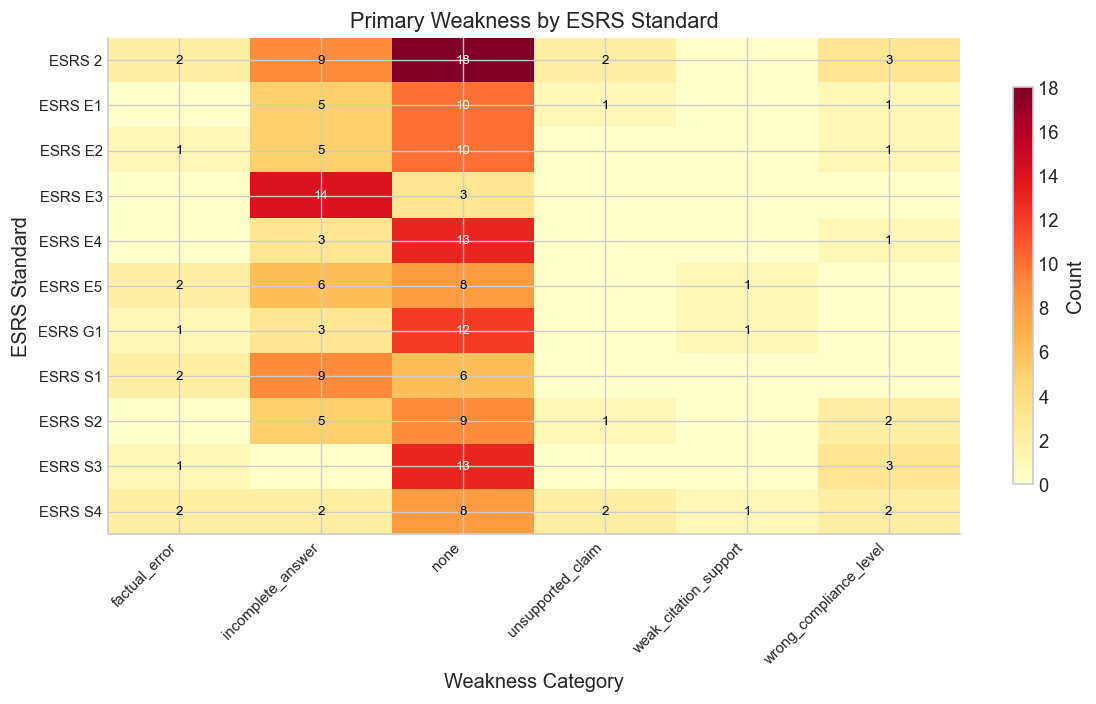

Heatmap saved to /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/data/artifacts/evaluation_results/rq3/rq3_weakness_heatmap.png


In [18]:
# --- Cross-tabulate primary_weakness x esrs_standard ---
weakness_types = sorted(set(s["judge"].primary_weakness for s in rq3_samples))

cross_data = []
for std in standards_list:
    std_samples = [s for s in rq3_samples if s["esrs_standard"] == std]
    row = {"Standard": std}
    weakness_counter = Counter(s["judge"].primary_weakness for s in std_samples)
    for w in weakness_types:
        row[w] = weakness_counter.get(w, 0)
    cross_data.append(row)

cross_df = pd.DataFrame(cross_data).set_index("Standard")

# Print table
print(cross_df.to_string())

# Heatmap
fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(cross_df.values, aspect="auto", cmap="YlOrRd")

ax.set_xticks(range(len(weakness_types)))
ax.set_xticklabels(weakness_types, rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(len(standards_list)))
ax.set_yticklabels(standards_list, fontsize=9)

# Annotate cells with counts
for i in range(len(standards_list)):
    for j in range(len(weakness_types)):
        val = cross_df.values[i, j]
        if val > 0:
            ax.text(j, i, str(int(val)), ha="center", va="center", fontsize=8,
                    color="white" if val > cross_df.values.max() / 2 else "black")

ax.set_title("Primary Weakness by ESRS Standard", fontsize=13)
ax.set_xlabel("Weakness Category")
ax.set_ylabel("ESRS Standard")
fig.colorbar(im, ax=ax, label="Count", shrink=0.8)
plt.tight_layout()
plt.savefig(RQ3_RESULTS_DIR / "rq3_weakness_heatmap.png")
plt.show()
print(f"Heatmap saved to {RQ3_RESULTS_DIR / 'rq3_weakness_heatmap.png'}")

### 7.5 Lowest-Scoring Samples (Bottom 10)

Sort all 204 samples by the judge's overall mean score and display the
bottom 10. These are the pipeline's worst-case failures and are valuable
for qualitative inspection: understanding *why* these specific samples
failed can guide targeted improvements to the prompt template, retrieval
parameters, or chunking strategy.

In [19]:
# --- Bottom 10 samples by judge mean score ---
sorted_samples = sorted(rq3_samples, key=lambda s: s["judge"].mean_score)
bottom_10 = sorted_samples[:10]

print(f"{'#':>2s}  {'QID':<6s} {'Company':<20s} {'Standard':<12s} {'Gold':>5s} {'Pred':>5s} "
      f"{'Mean':>5s} {'Weakness':<25s}")
print("\u2500" * 88)

for rank, s in enumerate(bottom_10, 1):
    j = s["judge"]
    print(
        f"{rank:>2d}  {s['question_id']:<6s} {s['company']:<20s} {s['esrs_standard']:<12s} "
        f"{s['gold_level']:>5s} {s['pred_level']:>5s} {j.mean_score:>5.2f} "
        f"{j.primary_weakness:<25s}"
    )

# Show detailed judge explanation for the worst sample
worst = bottom_10[0]
print(f"\n--- Worst sample details ---")
print(f"Question: {worst['question_id']} | Company: {worst['company']}")
print(f"Standard: {worst['esrs_standard']} | Disclosure: {worst['esrs_disclosure_id']}")
print(f"Judge scores: FC={worst['judge'].factual_correctness}, "
      f"CO={worst['judge'].completeness}, "
      f"GF={worst['judge'].grounding_faithfulness}, "
      f"CU={worst['judge'].citation_usefulness}, "
      f"CA={worst['judge'].compliance_assessment_quality}")
print(f"Weakness: {worst['judge'].primary_weakness}")
print(f"Explanation: {worst['judge'].judge_explanation}")

 #  QID    Company              Standard      Gold  Pred  Mean Weakness                 
────────────────────────────────────────────────────────────────────────────────────────
 1  Q11    OMV                  ESRS S4        Low  High  1.20 factual_error            
 2  Q11    Petrom               ESRS S4        Low Medium  1.40 wrong_compliance_level   
 3  Q11    Eni                  ESRS S4        Low  High  1.80 factual_error            
 4  Q9     Motoroil             ESRS S2        Low  High  2.20 wrong_compliance_level   
 5  Q11    Helleniq             ESRS S4        Low  High  2.20 wrong_compliance_level   
 6  Q10    Solvay               ESRS S3        Low Medium  2.40 factual_error            
 7  Q10    Vopak                ESRS S3        Low Medium  2.40 wrong_compliance_level   
 8  Q1     Equinor              ESRS 2        High  High  2.60 incomplete_answer        
 9  Q1     Shell                ESRS 2        High  High  2.80 incomplete_answer        
10  Q5     Repsol 

## 8. Persist Results

Save all per-sample results to a CSV file for downstream analysis and
a consolidated summary JSON for the thesis write-up. The CSV retains
`pred_level` and `gold_level` columns as contextual reference. No
compliance-label classification metrics are computed here -- those
belong to RQ2.

In [20]:
# --- Persist all RQ3 sample results for later analysis ---
rq3_rows = []
for s in rq3_samples:
    j = s["judge"]
    rq3_rows.append({
        "question_id": s["question_id"],
        "company": s["company"],
        "esrs_standard": s["esrs_standard"],
        "esrs_disclosure_id": s["esrs_disclosure_id"],
        "gold_level": s["gold_level"],
        "pred_level": s["pred_level"],
        "cite_precision": s.get("cite_precision", None),
        "cite_recall": s.get("cite_recall", None),
        "cite_f1": s.get("cite_f1", None),
        "recall_at_15": s.get("recall_at_15", None),
        # Judge dimensions
        "factual_correctness": j.factual_correctness,
        "completeness": j.completeness,
        "grounding_faithfulness": j.grounding_faithfulness,
        "citation_usefulness": j.citation_usefulness,
        "compliance_assessment_quality": j.compliance_assessment_quality,
        "judge_mean_score": j.mean_score,
        "primary_weakness": j.primary_weakness,
        "judge_explanation": j.judge_explanation,
    })

rq3_df = pd.DataFrame(rq3_rows)
rq3_csv_path = RQ3_RESULTS_DIR / "rq3_sample_results.csv"
rq3_df.to_csv(rq3_csv_path, index=False, encoding="utf-8")
print(f"RQ3 sample results saved: {rq3_csv_path} ({len(rq3_df)} rows)")

RQ3 sample results saved: /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/data/artifacts/evaluation_results/rq3/rq3_sample_results.csv (204 rows)


In [21]:
# --- Build and persist summary ---
summary = {
    "rq3_condition": RQ3_CONDITION,
    "esrs_context_helps": ESRS_CONTEXT_HELPS,
    "n_samples": len(rq3_samples),
    "citation_metrics": {
        "method": "range_overlap",
        "tolerance_pages": CITE_TOLERANCE,
        "precision": cite_prec_ci,
        "recall": cite_rec_ci,
        "f1": cite_f1_ci,
    },
    "judge_dimension_scores": {
        dim: {"mean": dim_cis[dim]["mean"], "ci_lower": dim_cis[dim]["ci_lower"],
              "ci_upper": dim_cis[dim]["ci_upper"]}
        for dim in DIMENSION_NAMES
    },
    "judge_overall_mean": {
        "mean": overall_ci["mean"],
        "ci_lower": overall_ci["ci_lower"],
        "ci_upper": overall_ci["ci_upper"],
    },
    "weakness_distribution": dict(weakness_counts),
}

summary_path = RQ3_RESULTS_DIR / "rq3_summary.json"
summary_path.write_text(json.dumps(summary, indent=2, default=str), encoding="utf-8")
print(f"Summary saved: {summary_path}")

Summary saved: /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/data/artifacts/evaluation_results/rq3/rq3_summary.json


## 9. Summary

Print a consolidated view of all RQ3 findings: citation page overlap metrics
and LLM judge dimension scores with confidence intervals.

In [22]:
# --- Print final summary ---
print("=" * 72)
print("RQ3 RESULTS -- Generation Quality Characterisation")
print("=" * 72)
print(f"\nSamples evaluated: {len(rq3_samples)}")
print(f"ESRS context injection benefit (RQ2): {'Yes' if ESRS_CONTEXT_HELPS else 'Null result'}")

print(f"\nA. CITATION PAGE METRICS")
print(f"   Precision: {cite_prec_ci['mean']:.4f}  [{cite_prec_ci['ci_lower']:.4f}, {cite_prec_ci['ci_upper']:.4f}]")
print(f"   Recall:    {cite_rec_ci['mean']:.4f}  [{cite_rec_ci['ci_lower']:.4f}, {cite_rec_ci['ci_upper']:.4f}]")
print(f"   F1:        {cite_f1_ci['mean']:.4f}  [{cite_f1_ci['ci_lower']:.4f}, {cite_f1_ci['ci_upper']:.4f}]")

print(f"\nB. LLM JUDGE SCORES (1-5 scale)")
for dim in DIMENSION_NAMES:
    ci = dim_cis[dim]
    print(f"   {dim:<35s}  {ci['mean']:.3f}  [{ci['ci_lower']:.3f}, {ci['ci_upper']:.3f}]")
print(f"   {'Overall mean':<35s}  {overall_ci['mean']:.3f}  [{overall_ci['ci_lower']:.3f}, {overall_ci['ci_upper']:.3f}]")

print(f"\nC. WEAKNESS DISTRIBUTION")
for weakness, count in weakness_counts.most_common():
    pct = 100 * count / len(rq3_samples)
    print(f"   {weakness:<30s}  {count:>3d}  ({pct:.1f}%)")

RQ3 RESULTS -- Generation Quality Characterisation

Samples evaluated: 204
ESRS context injection benefit (RQ2): Null result

A. CITATION PAGE METRICS
   Precision: 0.5936  [0.5530, 0.6347]
   Recall:    0.8979  [0.8603, 0.9330]
   F1:        0.6890  [0.6511, 0.7261]

B. LLM JUDGE SCORES (1-5 scale)
   factual_correctness                  4.544  [4.422, 4.662]
   completeness                         4.196  [4.064, 4.324]
   grounding_faithfulness               4.588  [4.475, 4.696]
   citation_usefulness                  4.132  [4.044, 4.216]
   compliance_assessment_quality        4.299  [4.157, 4.436]
   Overall mean                         4.352  [4.249, 4.448]

C. WEAKNESS DISTRIBUTION
   none                            110  (53.9%)
   incomplete_answer                61  (29.9%)
   wrong_compliance_level           13  (6.4%)
   factual_error                    11  (5.4%)
   unsupported_claim                 6  (2.9%)
   weak_citation_support             3  (1.5%)
